# Volatility Regimes

## Research question
How persistent are interpretable market volatility states?

## Data
Source: Bundesnetzagentur | SMARD.de. Observed period: January 2023-18 November 2026; 63,843 native price intervals and 136,128 quarter-hours per core load/wind/solar series. Physical quantities are German net grid/load generation; prices cover DE-LU. Actuals and forecasts remain separate; no missing physical value is replaced by zero.

## Methodology and equations
Low/Normal/Elevated/Extreme use 2023 25th/75th/95th quantiles of lagged seven-day standard deviation. Estimate Pr(Rt=j | Rt-1=i) on subsequent hourly states without future smoothing.

In [1]:
from pathlib import Path
import os
import pandas as pd
from IPython.display import Image, display
root = Path.cwd() if Path('reports').exists() else Path.cwd().parent
os.chdir(root)


In [2]:
from power_risk.regimes.model import classify
f=pd.read_parquet('reports/volatility_metrics.parquet')
labels,cuts=classify(f.rolling_std_7d.shift(),pd.Timestamp('2024-01-01',tz='Europe/Berlin'))
display(pd.Series(cuts,index=['q25','q75','q95']))
display(pd.read_csv('reports/regime_transitions.csv',index_col=0))
risk=pd.read_csv('reports/portfolio_risk_enhanced.csv')
display(risk.loc[risk.grouping.eq('regime')])

q25    31.440417
q75    43.818682
q95    57.151066
dtype: float64

,Low,Normal,Elevated,Extreme
regime,,,,
Low,0.993333,0.006667,0.000000,0.000000
Normal,0.004647,0.986809,0.008544,0.000000
Elevated,0.000000,0.007159,0.987471,0.005369
Extreme,0.000000,0.000000,0.007026,0.992974


,case,grouping,group,scenarios,confidence,mean_pnl_eur,var_loss_eur,expected_shortfall_loss_eur
5,purchaser,regime,Elevated,398,0.95,328.617858,1033.158000,1817.127487
6,purchaser,regime,Extreme,263,0.95,-421.463184,2675.721750,4281.994116
7,purchaser,regime,Low,285,0.95,340.028439,951.858500,1276.466491
8,purchaser,regime,Normal,465,0.95,94.891882,1302.656000,2350.443548
14,solar,regime,Elevated,398,0.95,-223.788287,656.909217,806.174454
15,solar,regime,Extreme,263,0.95,-179.940709,641.580275,943.603934
16,solar,regime,Low,285,0.95,-54.050580,270.674831,370.861459
17,solar,regime,Normal,465,0.95,-117.424520,501.696529,661.448078
23,wind,regime,Elevated,398,0.95,-156.307009,775.470648,1151.914794
24,wind,regime,Extreme,263,0.95,6.548672,710.897035,1131.236279


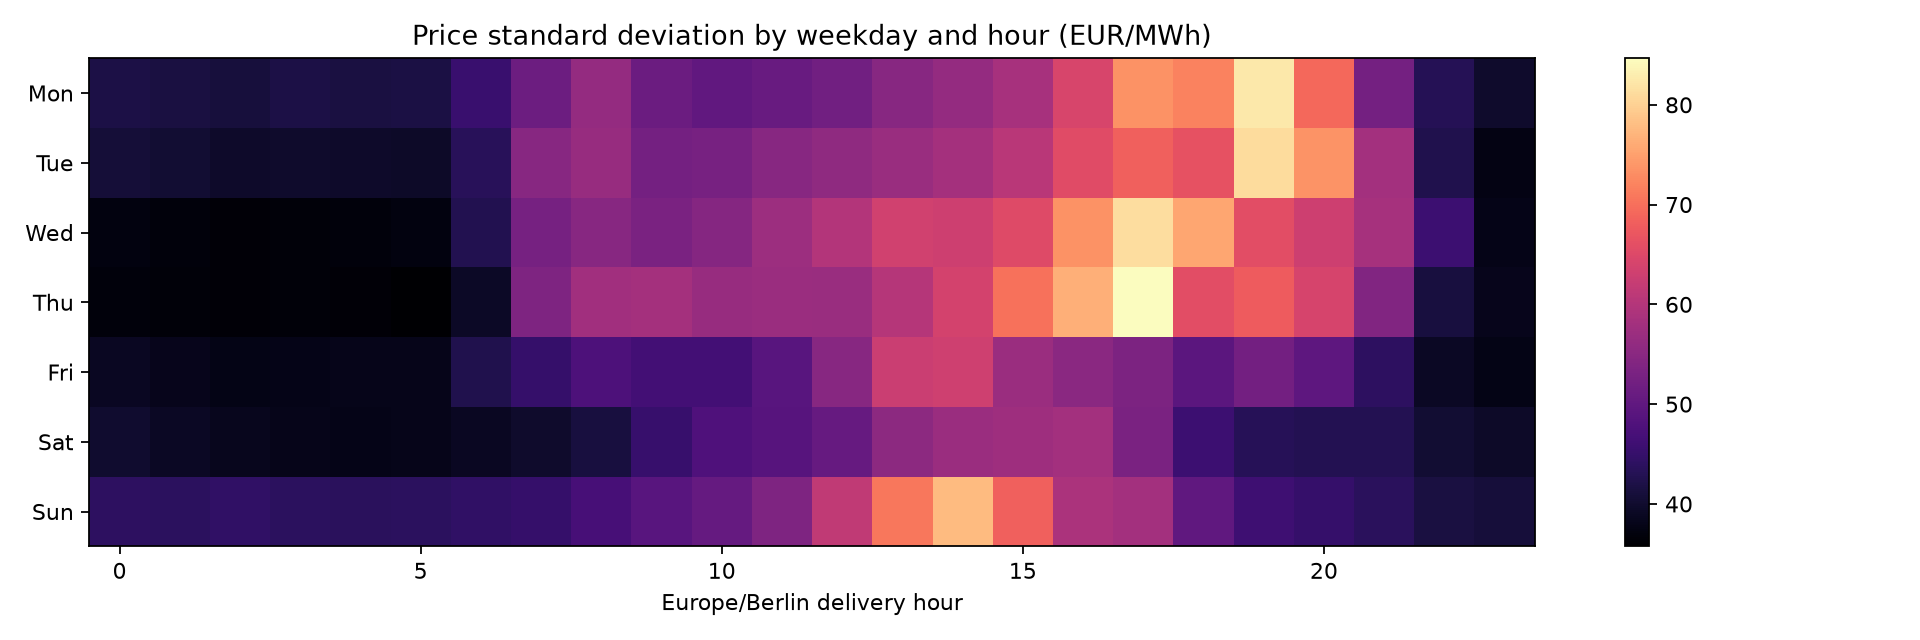

In [3]:
display(Image(filename='reports/volatility_heatmap.png'))

## Quantitative findings and commercial interpretation
The displayed transition probabilities quantify persistence; conditional portfolio losses differ across states. Scenario counts are essential because small extreme-state samples produce unstable tails.

## Limitations
Overlapping windows mechanically increase persistence. Labels are descriptive rather than causal latent states or hedge recommendations. 2023 portfolio state labels are in-calibration descriptions.

Calculations call reusable modules; regenerate underlying outputs using the README workflow.